# Simple Simulation Walkthrough

Este notebook parte da perspectiva de um usuário da biblioteca. Construiremos uma simulação do zero, inclusive implementando algoritmos próprios a partir das classes abstratas fornecidas pelo simulador.

O cenário terá três UAVs:

- **UAV A** e **UAV B** possuem planos que se cruzam. O conflito será resolvido estrategicamente antes da decolagem.
- **UAV C** encontrará uma geofence adicionada durante o voo. O conflito será detectado e resolvido taticamente.
- A execução será gravada incrementalmente em SQLite e, ao final, geraremos métricas, imagens e uma animação.

## 1. Preparação

A célula abaixo permite executar o notebook tanto pela raiz do repositório quanto pela própria pasta `Walkthrough`.

In [70]:
from pathlib import Path
import sys

CURRENT_DIRECTORY = Path.cwd().resolve()
PROJECT_ROOT = (
    CURRENT_DIRECTORY
    if (CURRENT_DIRECTORY / "pyproject.toml").exists()
    else CURRENT_DIRECTORY.parent
)
SOURCE_ROOT = PROJECT_ROOT / "src"
if str(SOURCE_ROOT) not in sys.path:
    sys.path.insert(0, str(SOURCE_ROOT))

OUTPUT_DIRECTORY = PROJECT_ROOT / "Walkthrough" / "outputs"
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)
DATASET_PATH = OUTPUT_DIRECTORY / "simple_simulation.sqlite"

print("Project root:", PROJECT_ROOT)
print("Outputs:", OUTPUT_DIRECTORY)

Project root: /Users/caiobianchi/Desktop/ITA/TG/TG_codigo
Outputs: /Users/caiobianchi/Desktop/ITA/TG/TG_codigo/Walkthrough/outputs


## 2. Imports do simulador

As interfaces são classes abstratas (`ABC`). Todo algoritmo injetado na `Simulation` deve herdar explicitamente da interface correspondente e implementar seus métodos abstratos. Assim, uma implementação incompleta falha já na instanciação.

In [71]:
from dataclasses import dataclass
from math import dist, hypot
import math
from typing import Sequence

import matplotlib.pyplot as plt
from IPython.display import Image, display

from utm_simulator.airspace.airspace import Airspace
from utm_simulator.airspace.geometry import Cylinder3D
from utm_simulator.airspace.restrictions import Geofence
from utm_simulator.algorithms.builtins.first_order_dynamics import FirstOrderDynamics
from utm_simulator.algorithms.builtins.perfect_sensor import PerfectSensor
from utm_simulator.algorithms.builtins.waypoint_guidance import WaypointGuidance
from utm_simulator.algorithms.interfaces.conflict_prediction import ConflictPredictionAlgorithm
from utm_simulator.algorithms.interfaces.strategic_deconfliction import StrategicDeconflictionAlgorithm
from utm_simulator.algorithms.interfaces.tactical_conflict_prediction import TacticalConflictPredictionAlgorithm
from utm_simulator.algorithms.interfaces.tactical_deconfliction import TacticalDeconflictionAlgorithm
from utm_simulator.algorithms.interfaces.tracking import TrackingAlgorithm
from utm_simulator.domain.flight import Conflict, FlightPlan, Waypoint
from utm_simulator.domain.message_types import StrategicDecision
from utm_simulator.domain.tracking import PredictedState, TrackPrediction, TrackingReport
from utm_simulator.simulation import (
    Simulation,
    SimulationDataset,
    VisualizationConfig,
    animate_dataset,
    plot_dataset,
)
from utm_simulator.uav.uav import UAVStatus

## 3. Funções geométricas auxiliares

Nosso predictor estratégico comparará posições interpoladas ao longo dos planos de voo. Estas funções pertencem ao algoritmo do usuário, não ao núcleo do simulador.

In [72]:
def position_at(flight_plan: FlightPlan, timestamp: float) -> list[float]:
    """Interpolate a position along a time-ordered flight plan."""
    waypoints = flight_plan.waypoint_list
    if timestamp <= waypoints[0].t:
        return waypoints[0].position()
    if timestamp >= waypoints[-1].t:
        return waypoints[-1].position()

    for start, end in zip(waypoints, waypoints[1:]):
        if start.t <= timestamp <= end.t:
            duration = end.t - start.t
            if duration <= 0:
                return end.position()
            fraction = (timestamp - start.t) / duration
            return [
                initial + fraction * (final - initial)
                for initial, final in zip(start.position(), end.position())
            ]

    return waypoints[-1].position()


def sampled_times(start: float, end: float, step: float):
    timestamp = start
    while timestamp <= end + 1e-9:
        yield timestamp
        timestamp += step


def separation(first, second) -> tuple[float, float]:
    horizontal = hypot(first[0] - second[0], first[1] - second[1])
    vertical = abs(first[2] - second[2])
    return horizontal, vertical

## 4. Representações de conflitos

`Conflict` é propositalmente uma classe-base vazia. Cada usuário pode representar conflitos da maneira mais adequada ao seu algoritmo. Aqui utilizaremos duas dataclasses simples.

In [73]:
@dataclass(frozen=True)
class UAVSeparationConflict(Conflict):
    uav_name: str
    other_uav_name: str
    timestamp: float
    horizontal_distance: float
    vertical_distance: float


@dataclass(frozen=True)
class AirspaceConflict(Conflict):
    uav_name: str
    object_id: str
    timestamp: float
    position: tuple[float, float, float]

## 5. Predictor estratégico

O predictor amostra os intervalos temporais compartilhados entre a proposta e os planos já aprovados. Também verifica restrições do espaço aéreo que estejam visíveis no instante da análise.

In [74]:
class UserStrategicConflictPrediction(ConflictPredictionAlgorithm):
    def __init__(
        self,
        horizontal_separation: float = 20.0,
        vertical_separation: float = 15.0,
        sampling_step: float = 0.25,
    ) -> None:
        self.horizontal_separation = horizontal_separation
        self.vertical_separation = vertical_separation
        self.sampling_step = sampling_step

    def predict(
        self,
        proposed_flight_plan: FlightPlan,
        approved_flight_plans: dict[str, FlightPlan],
        airspace: Airspace,
    ) -> list[Conflict]:
        conflicts: list[Conflict] = []
        proposal_start = proposed_flight_plan.waypoint_list[0].t
        proposal_end = proposed_flight_plan.waypoint_list[-1].t

        for other_name, other_plan in approved_flight_plans.items():
            start = max(proposal_start, other_plan.waypoint_list[0].t)
            end = min(proposal_end, other_plan.waypoint_list[-1].t)
            if start > end:
                continue

            for timestamp in sampled_times(start, end, self.sampling_step):
                proposed_position = position_at(proposed_flight_plan, timestamp)
                other_position = position_at(other_plan, timestamp)
                horizontal, vertical = separation(
                    proposed_position, other_position
                )
                if (
                    horizontal < self.horizontal_separation
                    and vertical < self.vertical_separation
                ):
                    conflicts.append(
                        UAVSeparationConflict(
                            uav_name="PROPOSED",
                            other_uav_name=other_name,
                            timestamp=timestamp,
                            horizontal_distance=horizontal,
                            vertical_distance=vertical,
                        )
                    )
                    break

        for timestamp in sampled_times(
            proposal_start, proposal_end, self.sampling_step
        ):
            position = position_at(proposed_flight_plan, timestamp)
            for region in airspace.prohibited_regions_at(position, timestamp):
                object_id = getattr(
                    region, "geofence_id", getattr(region, "obstacle_id", "unknown")
                )
                conflicts.append(
                    AirspaceConflict(
                        uav_name="PROPOSED",
                        object_id=object_id,
                        timestamp=timestamp,
                        position=tuple(position),
                    )
                )
                return conflicts

        return conflicts

## 6. Desconflitamento estratégico

Para manter o exemplo legível, nossa estratégia deslocará verticalmente a proposta quando houver conflito. Um algoritmo de pesquisa poderia substituir esta classe sem alterar a `Simulation`.

In [75]:
class UserStrategicDeconfliction(StrategicDeconflictionAlgorithm):
    def __init__(self, altitude_offset: float = 40.0) -> None:
        self.altitude_offset = altitude_offset

    def deconflict(
        self,
        proposed_flight_plan: FlightPlan,
        conflicts: list[Conflict],
        approved_flight_plans: dict[str, FlightPlan],
        airspace: Airspace,
    ) -> tuple[StrategicDecision, FlightPlan | None, dict[str, FlightPlan]]:
        last_index = len(proposed_flight_plan.waypoint_list) - 1
        shifted_plan = FlightPlan([
            Waypoint(
                wp.x,
                wp.y,
                wp.z + (self.altitude_offset if 0 < index < last_index else 0),
                wp.t,
            )
            for index, wp in enumerate(proposed_flight_plan.waypoint_list)
        ])
        return StrategicDecision.COUNTER_PROPOSAL, shifted_plan, {}

## 7. Algoritmo de tracking

Este tracker usa o último report como estimativa e propaga sua velocidade medida de forma constante. Ele recebe o plano de voo porque a interface permite que implementações mais sofisticadas o utilizem.

In [76]:
class UserConstantVelocityTracking(TrackingAlgorithm):
    """Favor observed motion nearby and the flight plan farther ahead."""
    
    def __init__(
        self,
        correction_decay=0.18,
        initial_kinematic_weight=0.85,
        minimum_kinematic_weight=0.25,
        kinematic_weight_decay=0.10,
        reported_velocity_weight=0.35,
    ):
        self.correction_decay = float(correction_decay)
        self.initial_kinematic_weight = float(initial_kinematic_weight)
        self.minimum_kinematic_weight = float(minimum_kinematic_weight)
        self.kinematic_weight_decay = float(kinematic_weight_decay)
        self.reported_velocity_weight = float(reported_velocity_weight)

        if not 0 <= self.minimum_kinematic_weight <= 1:
            raise ValueError("minimum_kinematic_weight must be between 0 and 1")
        if not self.minimum_kinematic_weight <= self.initial_kinematic_weight <= 1:
            raise ValueError(
                "initial_kinematic_weight must be between "
                "minimum_kinematic_weight and 1"
            )
        if not 0 <= self.reported_velocity_weight <= 1:
            raise ValueError("reported_velocity_weight must be between 0 and 1")
        if self.correction_decay < 0 or self.kinematic_weight_decay < 0:
            raise ValueError("decay parameters must be non-negative")

    def predict(
        self,
        uav_name,
        report_history,
        flight_plan,
        prediction_start,
        prediction_horizon,
        prediction_step,
    ):
        latest = report_history[-1]
        estimated_velocity = self._estimate_velocity(report_history)
        planned_now = self._position_at(flight_plan, latest.timestamp)
        tracking_error = [
            actual - planned
            for actual, planned in zip(latest.position, planned_now)
        ]

        predicted_states = []
        previous_position = latest.position
        previous_timestamp = latest.timestamp
        for step_index in range(1, prediction_horizon + 1):
            timestamp = prediction_start + step_index * prediction_step
            lookahead = max(0.0, timestamp - latest.timestamp)
            planned_position = self._position_at(flight_plan, timestamp)
            remaining_error = math.exp(-self.correction_decay * lookahead)
            plan_corrected_position = [
                planned + remaining_error * error
                for planned, error in zip(planned_position, tracking_error)
            ]
            kinematic_position = [
                position + velocity * lookahead
                for position, velocity in zip(
                    latest.position,
                    estimated_velocity,
                )
            ]
            kinematic_weight = self._kinematic_weight(
                lookahead,
                latest.timestamp,
                flight_plan,
            )
            position = [
                kinematic_weight * kinematic
                + (1.0 - kinematic_weight) * plan_corrected
                for kinematic, plan_corrected in zip(
                    kinematic_position,
                    plan_corrected_position,
                )
            ]
            elapsed_since_previous = timestamp - previous_timestamp
            velocity = [
                (current - previous) / elapsed_since_previous
                for current, previous in zip(position, previous_position)
            ]
            predicted_states.append(
                PredictedState(
                    position=position,
                    velocity=velocity,
                    timestamp=timestamp,
                )
            )
            previous_position = position
            previous_timestamp = timestamp

        return TrackPrediction(
            uav_name=uav_name,
            estimated_state=PredictedState(
                position=latest.position.copy(),
                velocity=estimated_velocity,
                timestamp=latest.timestamp,
            ),
            predicted_states=tuple(predicted_states),
            generated_at=prediction_start,
        )

    def _kinematic_weight(self, lookahead, report_timestamp, flight_plan):
        if report_timestamp < flight_plan.waypoint_list[0].t:
            return 0.0
        return self.minimum_kinematic_weight + (
            self.initial_kinematic_weight - self.minimum_kinematic_weight
        ) * math.exp(-self.kinematic_weight_decay * lookahead)

    def _estimate_velocity(self, report_history):
        if len(report_history) < 2:
            return report_history[-1].velocity.copy()

        reports = sorted(report_history, key=lambda report: report.timestamp)
        latest_timestamp = reports[-1].timestamp
        duration = latest_timestamp - reports[0].timestamp
        if duration <= 0:
            return reports[-1].velocity.copy()

        time_scale = max(duration / 2.0, 1e-6)
        weights = [
            math.exp((report.timestamp - latest_timestamp) / time_scale)
            for report in reports
        ]
        weight_sum = sum(weights)
        mean_time = sum(
            weight * report.timestamp
            for weight, report in zip(weights, reports)
        ) / weight_sum
        time_variance = sum(
            weight * (report.timestamp - mean_time) ** 2
            for weight, report in zip(weights, reports)
        )
        if time_variance <= 1e-12:
            return reports[-1].velocity.copy()

        regression_velocity = []
        for dimension in range(3):
            mean_position = sum(
                weight * report.position[dimension]
                for weight, report in zip(weights, reports)
            ) / weight_sum
            covariance = sum(
                weight
                * (report.timestamp - mean_time)
                * (report.position[dimension] - mean_position)
                for weight, report in zip(weights, reports)
            )
            regression_velocity.append(covariance / time_variance)

        reported_velocity = [
            sum(
                weight * report.velocity[dimension]
                for weight, report in zip(weights, reports)
            ) / weight_sum
            for dimension in range(3)
        ]
        measured_weight = self.reported_velocity_weight
        return [
            (1.0 - measured_weight) * regression
            + measured_weight * reported
            for regression, reported in zip(
                regression_velocity,
                reported_velocity,
            )
        ]

    @staticmethod
    def _position_at(flight_plan, timestamp):
        waypoints = flight_plan.waypoint_list
        if timestamp <= waypoints[0].t:
            return waypoints[0].position()
        if timestamp >= waypoints[-1].t:
            return waypoints[-1].position()

        for start, end in zip(waypoints, waypoints[1:]):
            if start.t <= timestamp <= end.t:
                duration = end.t - start.t
                if duration <= 0:
                    return end.position()
                fraction = (timestamp - start.t) / duration
                return [
                    start_value + fraction * (end_value - start_value)
                    for start_value, end_value in zip(
                        start.position(),
                        end.position(),
                    )
                ]
        return waypoints[-1].position()


## 8. Predictor tático

O predictor procura violações nas posições previstas. Ele detecta tanto entrada em geofences/obstáculos quanto perda de separação entre tracks.

In [77]:
class UserTacticalConflictPrediction(TacticalConflictPredictionAlgorithm):
    def __init__(
        self,
        horizontal_separation: float = 15.0,
        vertical_separation: float = 10.0,
    ) -> None:
        self.horizontal_separation = horizontal_separation
        self.vertical_separation = vertical_separation

    @staticmethod
    def states(track: TrackPrediction):
        return (track.estimated_state, *track.predicted_states)

    def predict(
        self,
        updated_track: TrackPrediction,
        tracks: dict[str, TrackPrediction],
        airspace: Airspace,
    ) -> list[Conflict]:
        conflicts: list[Conflict] = []
        updated_states = self.states(updated_track)

        for state in updated_states:
            regions = airspace.prohibited_regions_at(
                state.position, state.timestamp
            )
            if regions:
                region = regions[0]
                object_id = getattr(
                    region, "geofence_id", getattr(region, "obstacle_id", "unknown")
                )
                conflicts.append(
                    AirspaceConflict(
                        uav_name=updated_track.uav_name,
                        object_id=object_id,
                        timestamp=state.timestamp,
                        position=tuple(state.position),
                    )
                )
                break

        for other_name, other_track in tracks.items():
            if other_name == updated_track.uav_name:
                continue
            other_states = self.states(other_track)
            for state in updated_states:
                closest = min(
                    other_states,
                    key=lambda candidate: abs(candidate.timestamp - state.timestamp),
                )
                if abs(closest.timestamp - state.timestamp) > 0.51:
                    continue
                horizontal, vertical = separation(
                    state.position, closest.position
                )
                if (
                    horizontal < self.horizontal_separation
                    and vertical < self.vertical_separation
                ):
                    conflicts.append(
                        UAVSeparationConflict(
                            uav_name=updated_track.uav_name,
                            other_uav_name=other_name,
                            timestamp=state.timestamp,
                            horizontal_distance=horizontal,
                            vertical_distance=vertical,
                        )
                    )
                    break

        return conflicts

## 9. Desconflitamento tático

Para uma geofence, criaremos um waypoint lateral antes de continuar ao destino. Para um conflito entre UAVs, elevaremos temporariamente um deles. O conjunto `_handled_uavs` evita emitir repetidamente a mesma manobra neste exemplo.

In [78]:
class UserTacticalDeconfliction(TacticalDeconflictionAlgorithm):
    def __init__(
        self,
        lateral_offset: float = 35.0,
        altitude_offset: float = 30.0,
    ) -> None:
        self.lateral_offset = lateral_offset
        self.altitude_offset = altitude_offset
        self._handled_uavs: set[str] = set()

    def deconflict(
        self,
        conflicts: list[Conflict],
        tracks: dict[str, TrackPrediction],
        flight_plans: dict[str, FlightPlan],
        airspace: Airspace,
    ) -> dict[str, FlightPlan]:
        updates: dict[str, FlightPlan] = {}

        for conflict in conflicts:
            uav_name = conflict.uav_name
            if uav_name in self._handled_uavs:
                continue
            track = tracks.get(uav_name)
            current_plan = flight_plans.get(uav_name)
            if track is None or current_plan is None:
                continue

            current = track.estimated_state
            destination = current_plan.waypoint_list[-1]
            maneuver_time = max(current.timestamp + 4.0, conflict.timestamp)
            arrival_time = max(destination.t, maneuver_time + 10.0)

            if isinstance(conflict, AirspaceConflict):
                maneuver = Waypoint(
                    conflict.position[0],
                    conflict.position[1] + self.lateral_offset,
                    current.position[2],
                    maneuver_time,
                )
            else:
                conflict_position = position_at(current_plan, conflict.timestamp)
                maneuver = Waypoint(
                    conflict_position[0],
                    conflict_position[1],
                    current.position[2] + self.altitude_offset,
                    maneuver_time,
                )

            updates[uav_name] = FlightPlan([
                Waypoint(*current.position, current.timestamp),
                maneuver,
                Waypoint(destination.x, destination.y, destination.z, arrival_time),
            ])
            self._handled_uavs.add(uav_name)

        return updates

## 10. Objetos dos algoritmos

As annotations abaixo documentam qual contrato cada objeto satisfaz. Além disso, cada classe herda explicitamente da sua interface abstrata, como exigido pela `Simulation`.

In [79]:
strategic_predictor: ConflictPredictionAlgorithm = (
    UserStrategicConflictPrediction()
)
strategic_deconflictor: StrategicDeconflictionAlgorithm = (
    UserStrategicDeconfliction()
)
tracking_algorithm: TrackingAlgorithm = UserConstantVelocityTracking()
tactical_predictor: TacticalConflictPredictionAlgorithm = (
    UserTacticalConflictPrediction()
)
tactical_deconflictor: TacticalDeconflictionAlgorithm = (
    UserTacticalDeconfliction()
)

print("User algorithms created.")

User algorithms created.


## 11. Planos e espaço aéreo

A geofence ainda não faz parte do `Airspace`. Ela será adicionada em `t=14`, evitando que o planejamento estratégico tenha conhecimento antecipado dessa restrição.

In [80]:
flight_plans = {
    "UAV A": FlightPlan([
        Waypoint(-100, 0, 100, 5),
        Waypoint(0, 0, 100, 15),
        Waypoint(100, 0, 100, 25),
    ]),
    "UAV B": FlightPlan([
        Waypoint(0, -100, 100, 5),
        Waypoint(0, 0, 100, 15),
        Waypoint(0, 100, 100, 25),
    ]),
    "UAV C": FlightPlan([
        Waypoint(-120, -80, 100, 5),
        Waypoint(120, -80, 100, 40),
    ]),
}

airspace = Airspace(obstacles=[], geofences=[], wind_zones=[])
dynamic_geofence = Geofence(
    geofence_id="dynamic-geofence",
    name="Pop-up restriction",
    geometry=Cylinder3D(
        center_x=0,
        center_y=-80,
        radius=18,
        minimum_z=70,
        maximum_z=130,
    ),
    active_from=14,
)

assert not airspace.geofences
print("Plans:", list(flight_plans))

Plans: ['UAV A', 'UAV B', 'UAV C']


## 12. Construção da `Simulation`

Aqui os algoritmos do usuário são conectados aos módulos do simulador. O SQLite é atualizado incrementalmente durante a execução.

In [81]:
simulation = Simulation(
    airspace=airspace,
    strategic_conflict_prediction_algorithm=strategic_predictor,
    strategic_deconfliction_algorithm=strategic_deconflictor,
    tracking_algorithm=tracking_algorithm,
    tactical_conflict_prediction_algorithm=tactical_predictor,
    tactical_deconfliction_algorithm=tactical_deconflictor,
    network_delay=0.05,
    flight_update_interval=0.1,
    trajectory_record_interval=0.2,
    report_interval=0.5,
    history_window=6,
    prediction_horizon=16,
    prediction_step=0.5,
    dataset_path=DATASET_PATH,
    dataset_flush_interval=5.0,
    dataset_metadata={"scenario": "simple_user_walkthrough"},
    overwrite_dataset=True,
)

for name, flight_plan in flight_plans.items():
    simulation.add_uav(
        name=name,
        flight_plan=flight_plan,
        dynamics_algorithm=FirstOrderDynamics(
            max_acceleration=12.0,
            velocity_time_constant=0.3,
        ),
        guidance_algorithm=WaypointGuidance(
            min_speed=0.0,
            max_speed=18.0,
        ),
        sensor_model=PerfectSensor(),
        waypoint_acceptance_radius=2.0,
    )

simulation.schedule_geofence(
    dynamic_geofence,
    activation_time=14.0,
)

print("Simulation assembled.")

Simulation assembled.


## 13. Execução

`run(until=...)` utiliza tempo simulado, não tempo real. Ao terminar, fechamos o recorder para garantir que todos os dados tenham sido persistidos.

In [82]:
result = simulation.run(until=60.0)
simulation.close()

for name, uav in result.uavs.items():
    print(
        name,
        "status=", uav.status.name,
        "plan versions=", len(result.flight_plan_history[name]),
    )

assert all(uav.status == UAVStatus.COMPLETED for uav in result.uavs.values())
assert len(result.flight_plan_history["UAV B"]) >= 1
assert len(result.flight_plan_history["UAV C"]) >= 2
print("Dataset written to:", result.dataset_path)

UAV A status= COMPLETED plan versions= 1
UAV B status= COMPLETED plan versions= 1
UAV C status= COMPLETED plan versions= 2
Dataset written to: /Users/caiobianchi/Desktop/ITA/TG/TG_codigo/Walkthrough/outputs/simple_simulation.sqlite


## 14. Inspeção de eventos

O SQLite é o registro completo da execução. Podemos consultar decisões estratégicas, detecções táticas e versões de planos sem depender dos objetos vivos da simulação.

In [83]:
with SimulationDataset.open(DATASET_PATH) as dataset:
    print("Run status:", dataset.run_status)
    print("UAVs:", dataset.uav_names)
    print("Trajectory samples:", dataset.table_count("trajectory"))
    print("Tracking reports:", dataset.table_count("tracking_reports"))
    print("Tracking states:", dataset.table_count("tracking_predictions"))
    strategic_events = dataset.get_events("CONFLICT_PREDICTION_COMPLETED")
    strategic_conflicts = sum(
        int(event.details["conflict_count"]) for event in strategic_events
    )
    print("Strategic conflicts:", strategic_conflicts)
    print("Tactical detections:", len(
        dataset.get_events("TACTICAL_CONFLICTS_DETECTED")
    ))
    print("Tactical interventions:", len(
        dataset.get_events("TACTICAL_UPDATES_ISSUED")
    ))

Run status: COMPLETED
UAVs: ('UAV A', 'UAV B', 'UAV C')
Trajectory samples: 900
Tracking reports: 180
Tracking states: 3009
Strategic conflicts: 1
Tactical detections: 1
Tactical interventions: 1


## 15. Métricas simples

Como exemplo, calcularemos a distância planejada, a distância executada e o número de alterações de plano de cada UAV.

In [84]:
def path_length(positions) -> float:
    return sum(dist(first, second) for first, second in zip(positions, positions[1:]))


with SimulationDataset.open(DATASET_PATH) as dataset:
    print(f"{'UAV':<8} {'planned':>10} {'executed':>10} {'extra':>10} {'changes':>8}")
    for name in dataset.uav_names:
        proposed = dataset.get_flight_plan(name, "proposed", 0)
        trajectory = dataset.get_trajectory(name)
        planned = path_length([wp.position() for wp in proposed.waypoint_list])
        executed = path_length([state.position for state in trajectory])
        versions = dataset.get_flight_plan_versions(name)
        first_authorized = dataset.get_flight_plan(name, "authorized", versions[0])
        proposed_signature = [wp.position() for wp in proposed.waypoint_list]
        authorized_signature = [
            wp.position() for wp in first_authorized.waypoint_list
        ]
        strategic_change = int(proposed_signature != authorized_signature)
        changes = strategic_change + max(0, len(versions) - 1)
        print(
            f"{name:<8} {planned:10.1f} {executed:10.1f} "
            f"{executed - planned:10.1f} {changes:8d}"
        )

UAV         planned   executed      extra  changes
UAV A         200.0      198.9       -1.1        0
UAV B         200.0      215.6       15.6        1
UAV C         240.0      256.7       16.7        1


## 16. Imagens 3D e vista superior

As visualizações são reconstruídas exclusivamente a partir do SQLite.

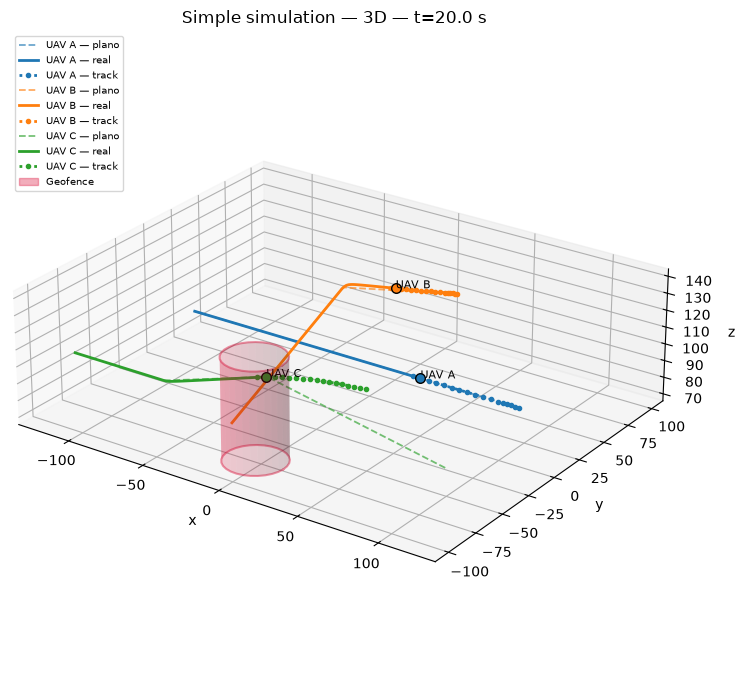

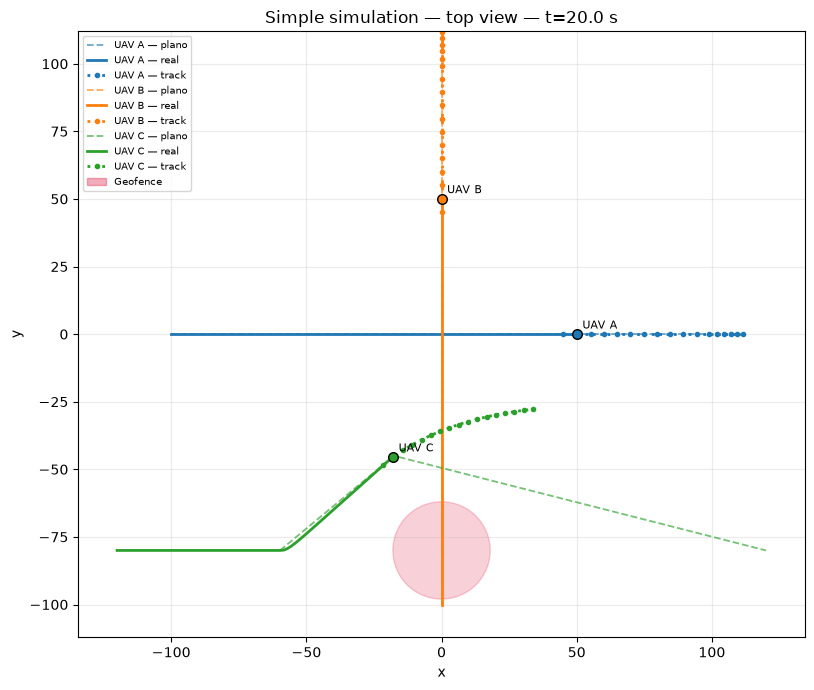

In [85]:
figure_3d = plot_dataset(
    DATASET_PATH,
    config=VisualizationConfig(
        view="3d",
        show_tracks=True,
        show_flight_plans=True,
        show_sensor_reports=False,
        show_geofences=True,
        title="Simple simulation — 3D",
    ),
    timestamp=20.0,
    output_path=OUTPUT_DIRECTORY / "simple_simulation_3d.png",
)
display(figure_3d)
plt.close(figure_3d)

figure_xy = plot_dataset(
    DATASET_PATH,
    config=VisualizationConfig(
        view="xy",
        show_tracks=True,
        show_flight_plans=True,
        show_geofences=True,
        title="Simple simulation — top view",
    ),
    timestamp=20.0,
    output_path=OUTPUT_DIRECTORY / "simple_simulation_xy.png",
)
display(figure_xy)
plt.close(figure_xy)

## 17. Animação

A linha pontilhada representa a prediction mais recente do tracking. O plano exibido muda somente quando a nova versão é efetivamente carregada pelo UAV.

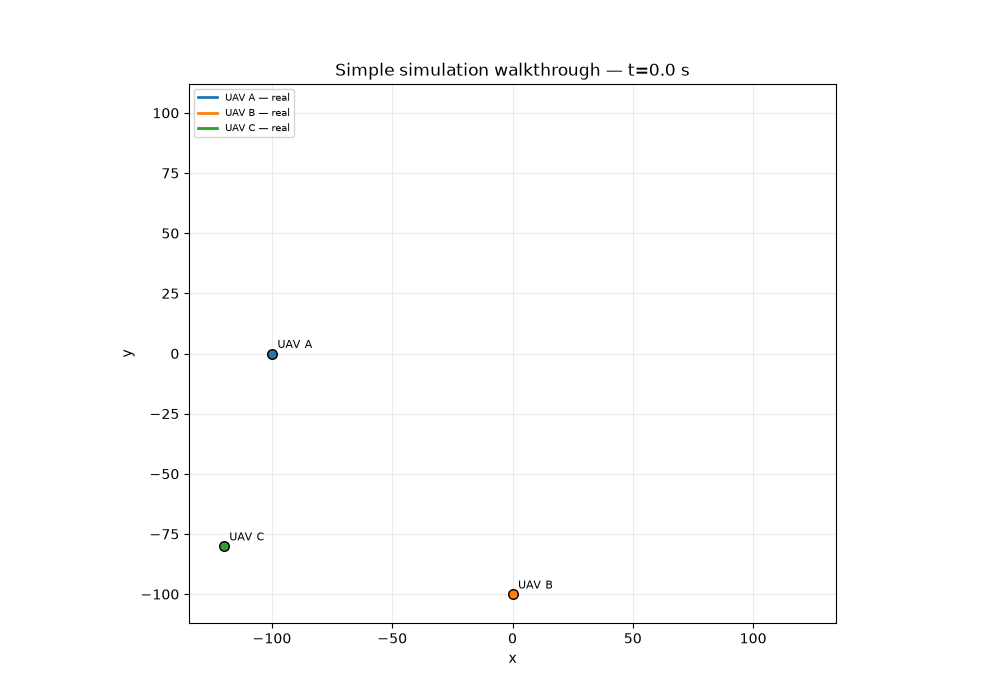

In [87]:
ANIMATION_PATH = OUTPUT_DIRECTORY / "simple_simulation.gif"
animation = animate_dataset(
    DATASET_PATH,
    config=VisualizationConfig(
        view="xy",
        show_tracks=True,
        show_flight_plans=True,
        show_sensor_reports=False,
        show_geofences=True,
        frame_step=1.0,
        title="Simple simulation walkthrough",
    ),
    output_path=ANIMATION_PATH,
    fps=8,
)
plt.close(animation._fig)
display(Image(filename=ANIMATION_PATH))

## Conclusão

Neste exemplo, o usuário forneceu todas as decisões algorítmicas enquanto o simulador cuidou da comunicação, do tempo discreto, do ciclo dos UAVs, do gerenciamento de planos, da persistência e das visualizações. Cada algoritmo deste notebook pode ser substituído independentemente por uma implementação mais sofisticada.